# Stability
1. Select cell types and samples from each tissue type that have a large number of cells.
3. Generate 10 70% subsamples of the RNA-seq and ATAC-seq datasets for each of the 10 sample cell types
4. Use the corresponding trained holdout model to generate cross-evaluation GRNs for each of the 10 subsamples
5. Generate GRNs for each of the 10 subsamples using the other GRN inference methods
6. Calculate the average pairwise Jaccard index for the 10 GRNs generated by my models and the other GRN inference methods

In [1]:
%matplotlib inline
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64,garbage_collection_threshold:0.6"

import sys
from pathlib import Path
from collections import Counter
import muon as mu
import logging
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import mudata
mudata.set_options(pull_on_update=False)
from matplotlib_inline import backend_inline
import matplotlib as mpl
import matplotlib.font_manager as fm

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
sys.path.append(str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR.parent / "data"
CHKPT_DIR = PROJECT_DIR / "checkpoints"

PROJECT_DATA_DIR = Path("/gpfs/Labs/Uzun/DATA/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

BINDING_MANIFEST = "binding_manifest.json"

backend_inline.set_matplotlib_formats('svg')

font_path = PROJECT_DIR / "fonts" / "Arial.ttf"

fm.fontManager.addfont(font_path)
arial_font = fm.FontProperties(fname=font_path).get_name()

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [arial_font, "Helvetica", "Liberation Sans", "DejaVu Sans"]

logging.info(f"Using font: {arial_font}")

2026-10-26 15:34:52.137627: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/gpfs/Home/esm5360/miniconda3/envs/my_env/lib/python3.10/site-packages/muon/_core/preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):
2026-10-26 15:36:23,003 - INFO - Using font: Arial


In [2]:
species = "mm10"

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
DATA_DIR = PROJECT_DIR.parent / "data"

# tissue type, dataset, sample name, cell type
sample_sources = [
    ("HSC", "GSE246464_HSC", "young_rep1", "HSC"),
    ("Liver", "mouse_liver", "liver_sample", "Hepatocytes"), # mouse_4
    ("Brain", "10x_E18_mouse_brain", "E18_brain", "Excitatory_neurons"),
    ("Embryo", "mESC", "E7.5_rep2", "Neurectoderm"),
    ("Kidney", "kidney", "Ctrl_4weeks_2", "Fibroblasts"),
    ("Skin", "GSE140203_shareseq", "skin_late_anagen", "Basal_keratinocytes"),
]

## Select the cells for each subsample

In [3]:
import json

percent_subsample = 0.7
num_subsamples = 10

subsample_cell_dict = {}

json_subsample_file = PROJECT_DATA_DIR / "subsample_cell_dict.json"

np.random.default_rng(42)
if json_subsample_file.exists():
    with open(json_subsample_file, "r") as f:
        subsample_cell_dict = json.load(f)
else:
    for tissue, dataset, sample_name, cell_type in sample_sources:
        input_data_dir = DATA_DIR / "processed" / dataset / sample_name
        assert input_data_dir.exists(), f"Input data directory does not exist: {input_data_dir}"
        
        subsample_cell_dict[tissue] = {
            "dataset": dataset,
            "cell_type": cell_type,
            "sample_name": sample_name,
            "subsamples": {}
        }

        mdata = mu.read(input_data_dir / "multiome_processed.h5mu", backed="r")
        try:
            rna_obs = mdata.mod["rna"].obs
            mask = rna_obs["celltype"].astype(str).str.lower().str.contains(cell_type.lower(), regex=False)
            if tissue == "Liver":
                mask &= rna_obs["donor"].astype(str) == "mouse_4"

            mdata_celltype = mdata[rna_obs.index[mask.to_numpy()]]
            n_cells = mdata_celltype.n_obs
            
            n_random_cells = int(n_cells *percent_subsample)
            
            # Randomly select cells for the subsamples
            for i in range(num_subsamples):
                cell_sample_ids = np.random.choice(mdata_celltype.obs_names, size=n_random_cells, replace=False)
                
                subsample_cell_dict[tissue]["subsamples"][f"subsample_{i}"] = list(cell_sample_ids)
        
        finally:
            mdata.file.close()
            
        with open(json_subsample_file, "w") as f:
            json.dump(subsample_cell_dict, f, indent=4)

## Run multiGRNtools

I created a script called `run_tools_stability.sh` in multiGRNtools. This uses the cell barcodes in the JSON subsample file to filter the count matrices to only the cells for each subsample using `filter_rna_atac_stability.py`. To save on disk usage, temporary RNA and ATAC raw filtered count matrices for only the selected cells are created while the other inference method is running, then deleted once the job ends.

## Load Stability GRNs

### multiGRNtools

In [4]:
other_method_grn_dir = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.GRN_BENCHMARKING.MOELLER/multiGRNtools/formatted_stability_GRNs_celltype/")

def load_multigrntools_stability_grns(other_method_grn_dir, subsample_cell_dict):
    other_method_grn_dict = {}
    for method_dir in other_method_grn_dir.iterdir():
        method_name = method_dir.name
        other_method_grn_dict[method_name] = {}
        print(f"Method: {method_name}")
            
        for tissue_type in subsample_cell_dict.keys():
            dataset = subsample_cell_dict[tissue_type]["dataset"]
            cell_type = subsample_cell_dict[tissue_type]["cell_type"]
            sample_name = subsample_cell_dict[tissue_type]["sample_name"]
            num_subsamples = len(subsample_cell_dict[tissue_type]["subsamples"].keys())
            
            existing_subsample_grns = 0
            other_method_subsamples = []
            for subsample_num in range(num_subsamples):
                grn_file = f"{method_name.lower().replace('_', '')}_{cell_type.replace(' ', '_')}_{sample_name}_sub{subsample_num}.tsv"
                if (other_method_grn_dir / method_name / grn_file).exists():
                    existing_subsample_grns += 1
                    other_method_grn = pd.read_csv(other_method_grn_dir / method_name / grn_file, sep="\t")
                    
                    other_method_grn["Method"] = method_name
                    other_method_grn["Tissue"] = tissue_type
                    other_method_grn["SampleID"] = sample_name
                    other_method_grn["CellType"] = cell_type
                    
                    other_method_grn["Source"] = other_method_grn["Source"].str.upper()
                    other_method_grn["Target"] = other_method_grn["Target"].str.upper()
                    
                    other_method_grn["subsample"] = subsample_num

                    other_method_subsamples.append(other_method_grn)
            other_method_grn_dict[method_name][tissue_type] = pd.concat(other_method_subsamples, ignore_index=True)
            print(f"  Stability GRNs for {tissue_type}: {existing_subsample_grns}/{num_subsamples}")
    return other_method_grn_dict

other_method_grn_dict = load_multigrntools_stability_grns(other_method_grn_dir, subsample_cell_dict)


Method: SCENIC_PLUS
  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stability GRNs for Embryo: 10/10
  Stability GRNs for Kidney: 10/10
  Stability GRNs for Skin: 10/10
Method: FigR
  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stability GRNs for Embryo: 10/10
  Stability GRNs for Kidney: 10/10
  Stability GRNs for Skin: 10/10
Method: CellOracle
  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stability GRNs for Embryo: 10/10
  Stability GRNs for Kidney: 10/10
  Stability GRNs for Skin: 10/10
Method: LINGER
  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stability GRNs for Embryo: 10/10
  Stability GRNs for Kidney: 10/10
  Stability GRNs for Skin: 10/10
Method: Pando
  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stabi

### MONICA

In [5]:
monica_grn_dir = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/testing_results/stability_results/celltype_holdout_models_tf_dna_3925194")

def load_monica_grns(monica_grn_dir: Path):
    monica_grn_dict = {"MONICA": {}}
    
    print("Method: MONICA")
    for tissue_type in subsample_cell_dict.keys():
        num_subsamples = len(subsample_cell_dict[tissue_type]["subsamples"].keys())
        
        existing_subsample_grns = 0
        monica_subsamples = []
        for subsample_num in range(num_subsamples):
            grn_file = f"subsample_{subsample_num}_grn.csv"
            if (monica_grn_dir / tissue_type / grn_file).exists():
                existing_subsample_grns += 1
                
                monica_grn = pd.read_csv(monica_grn_dir / tissue_type / grn_file)
                
                monica_grn["Method"] = "MONICA"
                monica_grn["Tissue"] = tissue_type
                monica_grn["subsample"] = subsample_num
                
                monica_subsamples.append(monica_grn)
        monica_grn_dict["MONICA"][tissue_type] = pd.concat(monica_subsamples, ignore_index=True)
        print(f"  Stability GRNs for {tissue_type}: {existing_subsample_grns}/{num_subsamples}")
        
    return monica_grn_dict

monica_grn_dict = load_monica_grns(monica_grn_dir)

Method: MONICA


  Stability GRNs for HSC: 10/10
  Stability GRNs for Liver: 10/10
  Stability GRNs for Brain: 10/10
  Stability GRNs for Embryo: 10/10
  Stability GRNs for Kidney: 10/10
  Stability GRNs for Skin: 10/10


In [6]:
monica_grn_dict["MONICA"]["Liver"]

,Tissue,SampleID,CellType,Source,Target,Score,Label,Method,subsample
0,Liver,liver_sample,Hepatocytes,CREB1,SUB1,0.233869,True,MONICA,0
1,Liver,liver_sample,Hepatocytes,CREB1,5730419F03RIK,0.157040,True,MONICA,0
2,Liver,liver_sample,Hepatocytes,JUN,GM5432,0.234754,False,MONICA,0
3,Liver,liver_sample,Hepatocytes,E2F4,RBAK,0.228585,False,MONICA,0
4,Liver,liver_sample,Hepatocytes,CTCF,TBC1D17,0.608966,True,MONICA,0
...,...,...,...,...,...,...,...,...,...
2603425,Liver,liver_sample,Hepatocytes,FOXA2,MRPL21,0.489898,True,MONICA,9
2603426,Liver,liver_sample,Hepatocytes,NR3C1,GM50368,0.426636,False,MONICA,9
2603427,Liver,liver_sample,Hepatocytes,NR1D1,SNX15,0.292060,True,MONICA,9
2603428,Liver,liver_sample,Hepatocytes,CEBPA,PPP1R14B,0.420178,True,MONICA,9


In [7]:
other_method_grn_dict["SCENIC_PLUS"]["Liver"]

,Source,Target,Score,Method,Tissue,SampleID,CellType,subsample
0,ARID5B,ABCA1,0.005037,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,0
1,ARID5B,ABCC2,0.003437,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,0
2,ARID5B,ACOX1,0.014191,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,0
3,ARID5B,ADHFE1,0.019379,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,0
4,ARID5B,AKAP9,0.004000,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,0
...,...,...,...,...,...,...,...,...
187554,ZKSCAN1,PCDHGB5,0.005740,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,9
187555,ZKSCAN1,PURG,0.008564,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,9
187556,ZKSCAN1,RBFOX3,0.000562,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,9
187557,ZKSCAN1,STXBP6,0.011175,SCENIC_PLUS,Liver,liver_sample,Hepatocytes,9


In [12]:
from scripts.model_evaluation.stability_jaccard import compute_stability

FORCE_RELOAD = True
top_pct = 0.1
full_method_dict = monica_grn_dict | other_method_grn_dict

cached_jaccard_file = PROJECT_DIR / "new_testing_results" / "jaccard_plot_data.parquet"
if not cached_jaccard_file.exists() or FORCE_RELOAD:
    
    # One cached parquet per (method, tissue); an entry is recomputed when its input GRNs change.
    jaccard_plot_df = compute_stability(
        full_method_dict,
        cache_dir=PROJECT_DIR / "new_testing_results" / "stability_jaccard_cache",
        top_pct=top_pct,
    )
    
    jaccard_plot_df.to_parquet(
        cached_jaccard_file,
        compression="gzip"
    )
else:
    jaccard_plot_df = pd.read_parquet(cached_jaccard_file)

30 cached, 6 to compute with n_jobs=12


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done   2 out of   6 | elapsed:   23.6s remaining:   47.2s
[Parallel(n_jobs=12)]: Done   3 out of   6 | elapsed:   25.5s remaining:   25.5s
[Parallel(n_jobs=12)]: Done   4 out of   6 | elapsed:   28.6s remaining:   14.3s
[Parallel(n_jobs=12)]: Done   6 out of   6 | elapsed:   39.1s finished


/tmp/ipykernel_1518948/417029300.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


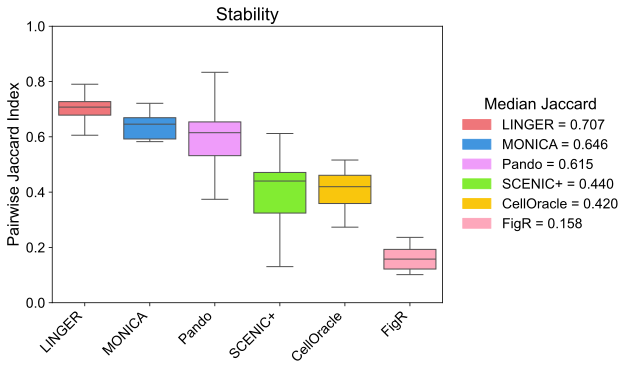

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

method_rename_map = {
    "MONICA": "MONICA",
    "LINGER": "LINGER",
    "SCENIC_PLUS": "SCENIC+",
    "CellOracle": "CellOracle",
    "FigR": "FigR",
}

method_color_dict = {
    "MONICA": "#4195df",
    "LINGER": "#EF767A",
    "CellOracle": "#F9C60D",
    "Pando": "#EF9CFA",
    "SCENIC_PLUS": "#82EC32",
    "FigR": "#FDA7BB",
    "GRaNIE": "#F98637",
}

def plot_method_stability_boxplot(jaccard_plot_df, method_rename_map, method_color_dict):
    fig, ax = plt.subplots(figsize=(7, 5))

    medians = (
        jaccard_plot_df.groupby("method_name")["jaccard_index"]
        .median()
        .sort_values(ascending=False)
    )
    median_order = medians.index

    sns.boxplot(
        data=jaccard_plot_df,
        x="method_name",
        y="jaccard_index",
        showfliers=False,
        hue="method_name",
        saturation=1,
        palette=method_color_dict,
        order=median_order,
        hue_order=median_order,
        legend=False,
        ax=ax,
    )

    ax.set_title("Stability", fontsize=18)
    ax.set_xticklabels(
        [method_rename_map.get(m, m) for m in median_order],
        rotation=45, ha="right", fontsize=14,
    )
    ax.tick_params(axis="y", labelsize=14)
    ax.set_ylabel("Pairwise Jaccard Index", fontsize=16)
    ax.set_xlabel("")
    ax.set_ylim(0, 1)

    # Pull the actual box colors seaborn used, so the legend matches exactly
    handles = [
        mpatches.Patch(
            color=method_color_dict[m],
            label=f"{method_rename_map.get(m, m)} = {medians[m]:.3f}",
        )
        for i, m in enumerate(median_order)
    ]

    ax.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=14,
        title="Median Jaccard",
        title_fontsize=16,
        frameon=False,
    )

    return fig, ax

stability_method_boxplot_fig, stability_method_boxplot_ax = plot_method_stability_boxplot(jaccard_plot_df, method_rename_map, method_color_dict)
stability_method_boxplot_fig.show()

stability_method_boxplot_fig.savefig(
    PROJECT_DIR / "new_plots" / "stability" / "stability_method_boxplot.png",
    bbox_inches="tight",
    dpi=300,
)

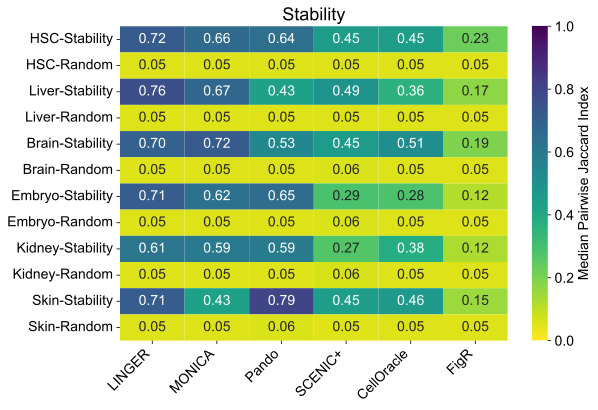

In [14]:
def plot_method_stability_heatmap(jaccard_plot_df, method_rename_map, tissue_rename_map=None):
    tissue_rename_map = tissue_rename_map or {}

    # Median over the 45 subsample pairs for each (method, tissue)
    med_df = (
        jaccard_plot_df
        .groupby(["method_name", "tissue_name"], sort=False)[["jaccard_index", "random_jaccard_index"]]
        .median()
        .rename(columns={"jaccard_index": "Stability", "random_jaccard_index": "Random"})
        .reset_index()
    )

    # Long -> one row per (tissue, kind), Stability on top and Random below
    long_df = med_df.melt(
        id_vars=["method_name", "tissue_name"],
        value_vars=["Stability", "Random"],
        var_name="kind",
        value_name="value",
    )
    heat = long_df.pivot_table(
        index=["tissue_name", "kind"],
        columns="method_name",
        values="value",
    )

    # Keep tissues in the order they appear in the data (the sample_sources order)
    tissue_order = list(dict.fromkeys(jaccard_plot_df["tissue_name"]))
    row_order = [(t, k) for t in tissue_order for k in ("Stability", "Random")]
    heat = heat.reindex([r for r in row_order if r in heat.index])
    # Methods left to right by overall median stability (same order as the boxplot)
    method_order = (
        jaccard_plot_df.groupby("method_name")["jaccard_index"]
        .median()
        .sort_values(ascending=False)
        .index
    )
    heat = heat.reindex(method_order, axis=1)

    fig, ax = plt.subplots(figsize=(1.1 * heat.shape[1] + 2, 0.4 * heat.shape[0] + 1))
    sns.heatmap(
        heat,
        annot=True,
        fmt=".2f",
        cmap="viridis_r",
        annot_kws={"fontsize": 14},
        vmin=0,
        vmax=1,
        square=False,
        ax=ax,
    )
    
    cbar = ax.collections[0].colorbar

    cbar.ax.tick_params(labelsize=14)

    cbar.set_label("Median Pairwise Jaccard Index", size=14)

    ax.set_yticklabels(
        [f"{tissue_rename_map.get(t, t)}-{k}" for (t, k) in heat.index],
        rotation=0, fontsize=14,
    )

    ax.set_xticklabels(
        [method_rename_map.get(m, m) for m in heat.columns],
        rotation=45, ha="right", fontsize=14,
    )

    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_title("Stability", fontsize=18)

    plt.tight_layout()

    return fig, ax

stability_heatmap_fig, stability_heatmap_ax = plot_method_stability_heatmap(jaccard_plot_df, method_rename_map)
stability_heatmap_fig.show()

stability_heatmap_fig.savefig(
    PROJECT_DIR / "new_plots" / "stability" / "stability_method_heatmap.png",
    bbox_inches="tight",
    dpi=300,
)